# 06 — Support vector machine (Oscar)

Can a support vector machine (SVM; Cortes & Vapnik, 1995) beat the logistic regression of `05-LogisticRegression.ipynb`?
The full working is in `Oscar/03-svm.ipynb`.

Run `01-Data.ipynb` first. Same features as the final logistic regression (fixes 1–4 + ratios) and the same 5
folds. Score to beat: logistic regression CV AUC 0.7722.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC

ROOT = Path.cwd().parent                  # run from report/
sys.path.append(str(ROOT / "Oscar"))
import prep                               # Oscar/prep.py: fixes 1-4 + ratio features

raw_train, y_train = prep.load("train")
X = prep.prepare(raw_train, ratios=True)                    # fixes 1-3 + ratios; scaling is done inside each fold
cv = StratifiedKFold(5, shuffle=True, random_state=2026)    # same folds as 05

print("X:", X.shape, f"  {y_train.mean():.2%} defaulted")

X: (17997, 61)   22.12% defaulted


## 1. First look

`SVC` gives scores, not probabilities, so AUC only for now (no log loss).

In [2]:
results, fold_auc = {}, {}      # name -> CV summary; name -> AUC on each fold

def cv_model(name, model):
    """5-fold CV AUC; standardising is learned inside each fold."""
    r = cross_validate(make_pipeline(StandardScaler(), model), X, y_train, cv=cv,
                       scoring="roc_auc", return_train_score=True)
    fold_auc[name] = r["test_score"]
    results[name] = {"auc": r["test_score"].mean(), "auc_sd": r["test_score"].std(),
                     "train_auc": r["train_score"].mean(), "fit_s": r["fit_time"].mean()}
    return pd.DataFrame.from_dict(results, orient="index").round(4)

def compare(ref="LR"):
    """AUC gain over `ref`, fold by fold: every model sat the same 5 folds."""
    gain = pd.DataFrame(fold_auc).sub(fold_auc[ref], axis=0)
    return pd.DataFrame({"mean gain": gain.mean(), "folds better": (gain > 0).sum()}).round(4)

cv_model("LR", LogisticRegression(C=0.0316, l1_ratio=0, solver="liblinear", max_iter=1000))   # final LR from 05
print(cv_model("SVM rbf (defaults)", SVC()), "\n")                                          # C=1, gamma="scale"
compare()

                       auc  auc_sd  train_auc   fit_s
LR                  0.7722  0.0140     0.7775  0.0583
SVM rbf (defaults)  0.7244  0.0112     0.8528  3.0921 



,mean gain,folds better
LR,0.0000,0
SVM rbf (defaults),-0.0478,0


The default radial basis function (RBF) SVM is worse than logistic regression on all 5 folds. It also
overfits: train AUC 0.85 against CV AUC 0.72. So we tune the hyperparameters to give the model less
flexibility.

## 2. Tuning C and gamma

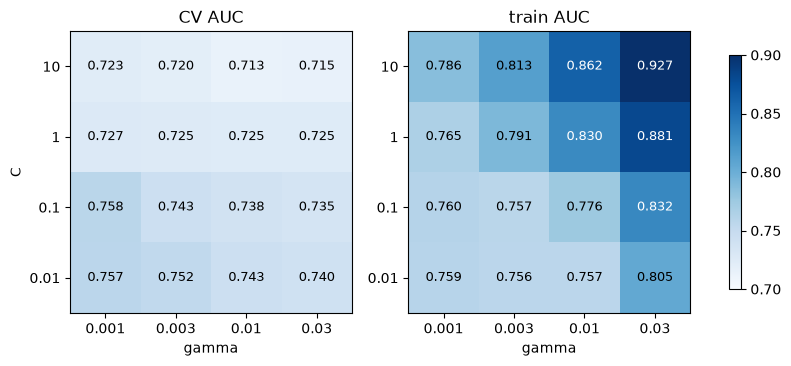

In [3]:
Cs = [0.01, 0.1, 1, 10]
gammas = [0.001, 0.003, 0.01, 0.03]     # default "scale" = 1 / (61 features x variance 1) ≈ 0.016

for C in Cs:                             # 16 settings x 5 folds; a few minutes
    for g in gammas:
        cv_model(f"rbf C={C} g={g}", SVC(C=C, gamma=g))

grid = pd.DataFrame([{"C": C, "gamma": g, **results[f"rbf C={C} g={g}"]} for C in Cs for g in gammas])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, col, title in [(axes[0], "auc", "CV AUC"), (axes[1], "train_auc", "train AUC")]:
    t = grid.pivot(index="C", columns="gamma", values=col)
    im = ax.imshow(t, cmap="Blues", vmin=0.70, vmax=0.90, origin="lower")   # same scale on both panels
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            v = t.iloc[i, j]
            ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=9,
                    color="white" if v > 0.82 else "black")
    ax.set(xticks=range(len(gammas)), xticklabels=gammas, yticks=range(len(Cs)), yticklabels=Cs,
           xlabel="gamma", title=title)
axes[0].set_ylabel("C")
fig.colorbar(im, ax=axes, shrink=0.8);

There is a clear pattern: anything that makes the boundary more flexible (bigger gamma, bigger C) makes CV
worse while train AUC shoots up (0.93 top right). The model is memorising the training customers.

The best setting is C = 0.1, gamma = 0.001 at 0.758: much better than the defaults (0.724), but still below
logistic regression. Train ≈ CV here, so it is no longer overfitting; it is just a weaker fit than logistic
regression.

The best value sits on the edge of the grid (smallest gamma), so we extend the grid once.

In [4]:
# tiny gamma needs larger C to fit anything
for C in [0.1, 1, 10]:
    for g in [0.0001, 0.0003]:
        cv_model(f"rbf C={C} g={g}", SVC(C=C, gamma=g))

grid = pd.DataFrame([{"C": float(k.split()[1][2:]), "gamma": float(k.split()[2][2:]), **v}
                     for k, v in results.items() if k.startswith("rbf C=")])
print(grid.pivot(index="C", columns="gamma", values="auc").round(4), "\n")

best = grid.loc[grid["auc"].idxmax()]
print(f"best: C={best['C']}, gamma={best['gamma']}, CV AUC {best['auc']:.4f}\n")
compare().sort_values("mean gain", ascending=False).head(6)

gamma  0.0001  0.0003  0.0010  0.0030  0.0100  0.0300
C                                                    
0.01      NaN     NaN  0.7569  0.7524  0.7432  0.7401
0.10   0.7583  0.7580  0.7576  0.7433  0.7381  0.7350
1.00   0.7584  0.7417  0.7273  0.7253  0.7245  0.7250
10.00  0.7306  0.7217  0.7232  0.7202  0.7134  0.7151 

best: C=1.0, gamma=0.0001, CV AUC 0.7584



,mean gain,folds better
LR,0.0000,0
rbf C=1 g=0.0001,-0.0138,0
rbf C=0.1 g=0.0001,-0.0139,1
rbf C=0.1 g=0.0003,-0.0143,1
rbf C=0.1 g=0.001,-0.0146,0
rbf C=0.01 g=0.001,-0.0153,1


Going smaller on gamma barely changes anything: the best is now C = 1, gamma = 0.0001 at 0.7584, only
+0.0008, which is well inside the noise between folds. The RBF SVM has plateaued at about 0.758 and more tuning
won't change that. It is still about 0.014 behind logistic regression and better on at most 1 of 5 folds.

With gamma this small the RBF kernel is close to linear, and its train AUC (about 0.76) is still below logistic
regression's (about 0.78). So the shape of the boundary is probably not what holds it back; the loss function is
more likely. The hinge loss ignores customers already on the right side of the margin, whereas logistic
regression's log loss uses everyone. We check this with a linear SVM next.

Bigger C at tiny gamma got worse, not better, which was unexpected. Chasing the misclassified customers may
disturb the ranking for everyone else.

## 3. Linear SVM: is it the loss?

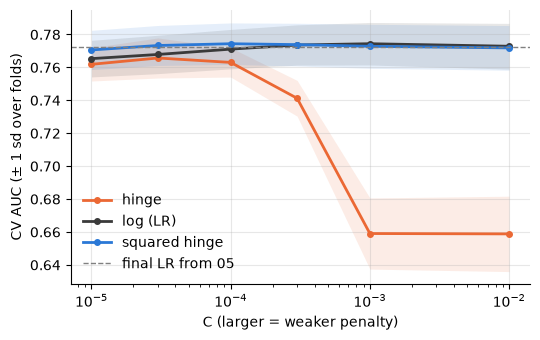

In [5]:
# same linear boundary, three losses; same C means the same penalty on the weights in all three
Cs_lin = [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 1e-2]
losses = {"hinge":         lambda C: LinearSVC(C=C, loss="hinge", dual=True, max_iter=20000),
          "squared hinge": lambda C: LinearSVC(C=C, loss="squared_hinge", dual=True, max_iter=20000),
          "log (LR)":      lambda C: LogisticRegression(C=C, l1_ratio=0, solver="liblinear", max_iter=1000)}

for loss, make in losses.items():
    for C in Cs_lin:
        cv_model(f"{loss} C={C:g}", make(C))

lin = pd.DataFrame([{"loss": loss, "C": C, **results[f"{loss} C={C:g}"]} for loss in losses for C in Cs_lin])

colours = {"hinge": "#eb6834", "squared hinge": "#2a78d6", "log (LR)": "#3a3a3a"}
fig, ax = plt.subplots(figsize=(5.5, 3.5))
for loss, d in lin.groupby("loss"):
    ax.plot(d["C"], d["auc"], "o-", color=colours[loss], lw=2, ms=4, label=loss)
    ax.fill_between(d["C"], d["auc"] - d["auc_sd"], d["auc"] + d["auc_sd"], color=colours[loss], alpha=0.12, lw=0)
ax.axhline(results["LR"]["auc"], color="grey", ls="--", lw=1, label="final LR from 05")
ax.set(xscale="log", xlabel="C (larger = weaker penalty)", ylabel="CV AUC (± 1 sd over folds)")
ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()

In [6]:
compare().loc[[f"{loss} C={C:g}" for loss in losses for C in Cs_lin]]

,mean gain,folds better
hinge C=1e-05,-0.0104,0
hinge C=3e-05,-0.0065,0
hinge C=0.0001,-0.0092,1
hinge C=0.0003,-0.0310,0
hinge C=0.001,-0.1132,0
hinge C=0.01,-0.1134,0
squared hinge C=1e-05,-0.0016,1
squared hinge C=3e-05,0.0011,2
squared hinge C=0.0001,0.0022,5
squared hinge C=0.0003,0.0016,5


It does look like the loss. Plain hinge is fine at tiny C (0.766) but falls off a cliff to about 0.65 as C
goes up, whereas squared hinge and logistic regression are almost the same line, both topping out at 0.7744. The
RBF SVM uses plain hinge, so this is probably what capped it at about 0.758 in section 2, and why bigger C made
it worse there.

The reason is what score each loss is aiming for (Zhang, 2004; Bartlett, Jordan & McAuliffe, 2006). Logistic
regression aims for log(p/(1−p)) and squared hinge for 2p−1, which both increase with p, so customers stay in
order. Hinge just aims for +1 if p > 0.5 and −1 otherwise. Almost nobody here is above 0.5, so everyone is pushed
towards the same score and the ordering is lost, and the ordering is exactly what AUC measures. At tiny C the
weights can't get big enough to do that, which is why hinge only works there.

Logistic regression at C = 0.001 also reaches 0.7744, better than the final logistic regression from `05`
(C = 0.0316) on all 5 folds. In `05` C was picked on log loss; here it is AUC. So the SVM only ties with logistic
regression once logistic regression is tuned on the same metric, and which C is "best" depends on the metric
the group agrees.

## 4. Final SVM and test set

> **TODO (Oscar):** not done yet in `Oscar/03-svm.ipynb`. Needs: choose the final SVM (squared hinge, C = 1e-4?);
get probabilities for log loss and calibration (e.g. Platt scaling, Platt 1999, via `CalibratedClassifierCV`);
check on validation; score once on test; save `data/output/predictions-svm.csv`.

## 5. Conclusion

> **TODO (Oscar):** once section 4 is done.

## References

- Bartlett, P. L., Jordan, M. I. & McAuliffe, J. D. (2006). Convexity, classification, and risk bounds.
  *Journal of the American Statistical Association* 101(473), 138–156.
  https://doi.org/10.1198/016214505000000907
- Cortes, C. & Vapnik, V. (1995). Support-vector networks. *Machine Learning* 20(3), 273–297.
  https://doi.org/10.1007/BF00994018
- Platt, J. (1999). Probabilistic outputs for support vector machines and comparisons to regularized likelihood
  methods. In *Advances in Large Margin Classifiers*, 61–74. MIT Press.
- Zhang, T. (2004). Statistical behavior and consistency of classification methods based on convex risk
  minimization. *The Annals of Statistics* 32(1), 56–85. https://doi.org/10.1214/aos/1079120130